# Crypt number and length by perturbation
Loads final mesh segmentations from `scripts/run_crypt_segmentation.py`; graphs and marker exclusivity are not involved. Each saved organoid contributes once, including organoids with zero crypts. Missing/failed segmentations are not treated as zero-crypt organoids.

Crypt length is the saved `L_crypts` axis-length proxy, rescaled to the detected neckline, not a straight-line distance or a fitted centerline length. The current segmentation run uses mesh-edge Dijkstra distances. Mesh coordinates were divided by 10 during normalization, so lengths are multiplied by 10 to recover micrometers.

Organoids are pooled across wells within each condition. Mean-count error bars describe between-organoid standard deviation, not uncertainty across independent wells. Length histograms pool individual crypts, so organoids with more crypts contribute more observations. No outlier trimming is applied.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'scripts/run_crypt_segmentation.py').is_file())
DATASET = 'perturbations_day3p5'
SEGMENTATION_DIR = PROJECT_ROOT.parent / 'NicoleData' / DATASET / 'crypt_segmentations_mesh'
SELECTED_TIMEPOINTS = ['day3p5']  # None includes all saved timepoints.
LENGTH_SCALE_UM = 10.0  # Original meshes in um; normalize_inplace(scale=10).
LENGTH_BINS = 25
EXPORT = True
EXPORT_DIR = PROJECT_ROOT / 'exports' / 'crypt_perturbations' / DATASET

CONDITIONS = {
    'C07': 'IWP2_60hr_HiWnt', 'C08': 'IWP2_60hr_HiWnt',
    'D02': 'control', 'D03': 'control',
    'D07': 'IWP2_60hr', 'D08': 'IWP2_60hr',
    'E02': 'IWP2_24hr', 'E03': 'IWP2_24hr',
}
CONDITION_ORDER = ['control', 'IWP2_24hr', 'IWP2_60hr', 'IWP2_60hr_HiWnt']
CONDITION_COLORS = dict(zip(CONDITION_ORDER, ['#666666', '#009E73', '#D55E00', '#0072B2']))
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
def well_from_label(label):
    matches = re.findall(r'(?:^|_)([A-H]\d{2})(?=_|$)', label.upper())
    if len(matches) != 1:
        raise ValueError(f'Expected one well in label_ID: {label!r}')
    return matches[0]


def load_segmentations(root, conditions, timepoints=None, length_scale_um=10.0):
    if not np.isfinite(length_scale_um) or length_scale_um <= 0:
        raise ValueError('length_scale_um must be finite and positive.')
    paths = sorted(Path(root).rglob('*.npz'))
    if not paths:
        raise FileNotFoundError(f'No segmentation NPZ files found under {root}')
    organoids, crypts, audit, seen = [], [], [], set()
    for path in paths:
        # Object arrays hold variable-length patches; load only trusted local files.
        with np.load(path, allow_pickle=True) as data:
            label = str(data['label_uid'].item()) if 'label_uid' in data else path.stem
            tp = str(data['timepoint'].item()) if 'timepoint' in data else path.parent.name
            if timepoints is not None and tp not in timepoints:
                audit.append({'source_file': str(path), 'reason': 'unselected timepoint'})
                continue
            well = well_from_label(label)
            if well not in conditions:
                audit.append({'source_file': str(path), 'reason': f'unmapped well {well}'})
                continue
            key = (tp, label)
            if key in seen:
                raise ValueError(f'Duplicate organoid: {key} ({path})')
            seen.add(key)
            n_crypts = len(data['crypts_ll'])
            if 'L_crypts' not in data:
                raise ValueError(f'Missing L_crypts in {path}')
            lengths = np.asarray(data['L_crypts'], dtype=float).reshape(-1)
            if len(lengths) != n_crypts:
                raise ValueError(f'Patch/length count mismatch in {path}')
            valid = np.isfinite(lengths) & (lengths > 0)
            identity = dict(label_ID=label, timepoint=tp, well=well,
                            condition=conditions[well], source_file=str(path))
            organoids.append(dict(**identity, n_crypts=n_crypts,
                                  n_valid_lengths=int(valid.sum())))
            for i, (length, is_valid) in enumerate(zip(lengths, valid), start=1):
                crypts.append(dict(**identity, crypt_id=i, length_mesh_units=length,
                                   length_um=length * length_scale_um, valid_length=bool(is_valid)))
    if not organoids:
        raise ValueError('No organoids match the configured timepoints and wells.')
    crypt_columns = [*organoids[0].keys()][:5] + [
        'crypt_id', 'length_mesh_units', 'length_um', 'valid_length']
    return (pd.DataFrame(organoids), pd.DataFrame(crypts, columns=crypt_columns),
            pd.DataFrame(audit, columns=['source_file', 'reason']))


def summarize_conditions(organoids, crypts, condition_order):
    rows = []
    for condition in condition_order:
        subset = organoids.loc[organoids.condition == condition]
        lengths = crypts.loc[(crypts.condition == condition) &
                            crypts.valid_length.astype(bool), 'length_um']
        counts = subset.n_crypts
        rows.append(dict(condition=condition, n_organoids=len(subset),
                         n_wells=subset.well.nunique(), n_crypts=int(counts.sum()),
                         n_zero_crypt_organoids=int((counts == 0).sum()),
                         mean_n_crypts=counts.mean(), sd_n_crypts=counts.std(ddof=1),
                         n_valid_lengths=len(lengths), mean_length_um=lengths.mean(),
                         sd_length_um=lengths.std(ddof=1)))
    return pd.DataFrame(rows)


In [3]:
organoid_table, crypt_table, skipped_files = load_segmentations(
    SEGMENTATION_DIR, CONDITIONS, SELECTED_TIMEPOINTS, LENGTH_SCALE_UM)
summary_table = summarize_conditions(organoid_table, crypt_table, CONDITION_ORDER)
print(f'Loaded {len(organoid_table)} organoids and {len(crypt_table)} final crypts.')
print(f'Invalid lengths excluded only from length plots: {int((~crypt_table.valid_length.astype(bool)).sum())}')
display(organoid_table.groupby(['condition', 'timepoint', 'well']).size().rename('n_organoids').to_frame())
display(summary_table)
if len(skipped_files):
    display(skipped_files)
missing = summary_table.loc[summary_table.n_organoids == 0, 'condition'].tolist()
if missing:
    print('Conditions with no saved organoids:', missing)


Loaded 889 organoids and 744 final crypts.
Invalid lengths excluded only from length plots: 0


n_organoids
condition       timepoint well             
IWP2_24hr       day3p5    E02           114
                          E03           122
IWP2_60hr       day3p5    D07           135
                          D08           114
IWP2_60hr_HiWnt day3p5    C07            68
                          C08            86
control         day3p5    D02           133
                          D03           117

,condition,n_organoids,n_wells,n_crypts,n_zero_crypt_organoids,mean_n_crypts,sd_n_crypts,n_valid_lengths,mean_length_um,sd_length_um
0,control,250,2,486,24,1.944000,0.967786,486,49.438369,15.928722
1,IWP2_24hr,236,2,127,153,0.538136,0.837059,127,54.753749,39.972916
2,IWP2_60hr,249,2,77,201,0.309237,0.716141,77,42.864491,19.617638
3,IWP2_60hr_HiWnt,154,2,54,119,0.350649,0.820748,54,66.290725,54.514908


## Mean crypt count
One observation per organoid, including zeros; error bars are sample standard deviations (ddof=1).

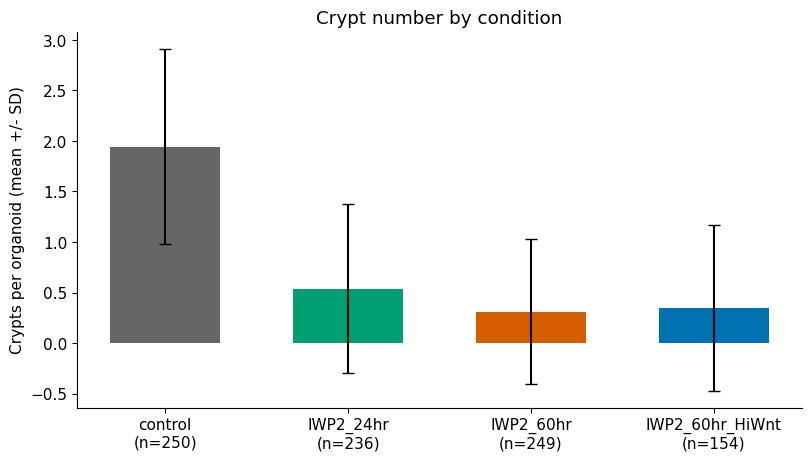

In [4]:
fig_mean, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for x, row in enumerate(summary_table.itertuples(index=False)):
    if row.n_organoids:
        ax.bar(x, row.mean_n_crypts, width=0.6, color=CONDITION_COLORS[row.condition])
        if np.isfinite(row.sd_n_crypts):
            ax.errorbar(x, row.mean_n_crypts, yerr=row.sd_n_crypts, color='black', capsize=4, fmt='none')
ax.set_xticks(range(len(CONDITION_ORDER)),
              [f'{r.condition}\n(n={r.n_organoids})' for r in summary_table.itertuples(index=False)])
ax.set_ylabel('Crypts per organoid (mean +/- SD)')
ax.set_title('Crypt number by condition')
plt.show()


## Within-condition distributions
Shared integer-centered bins for crypt counts and shared bins in micrometers for lengths allow comparison across conditions. Empty conditions are shown explicitly. Counts include all saved organoids; lengths include all finite, positive crypt lengths.

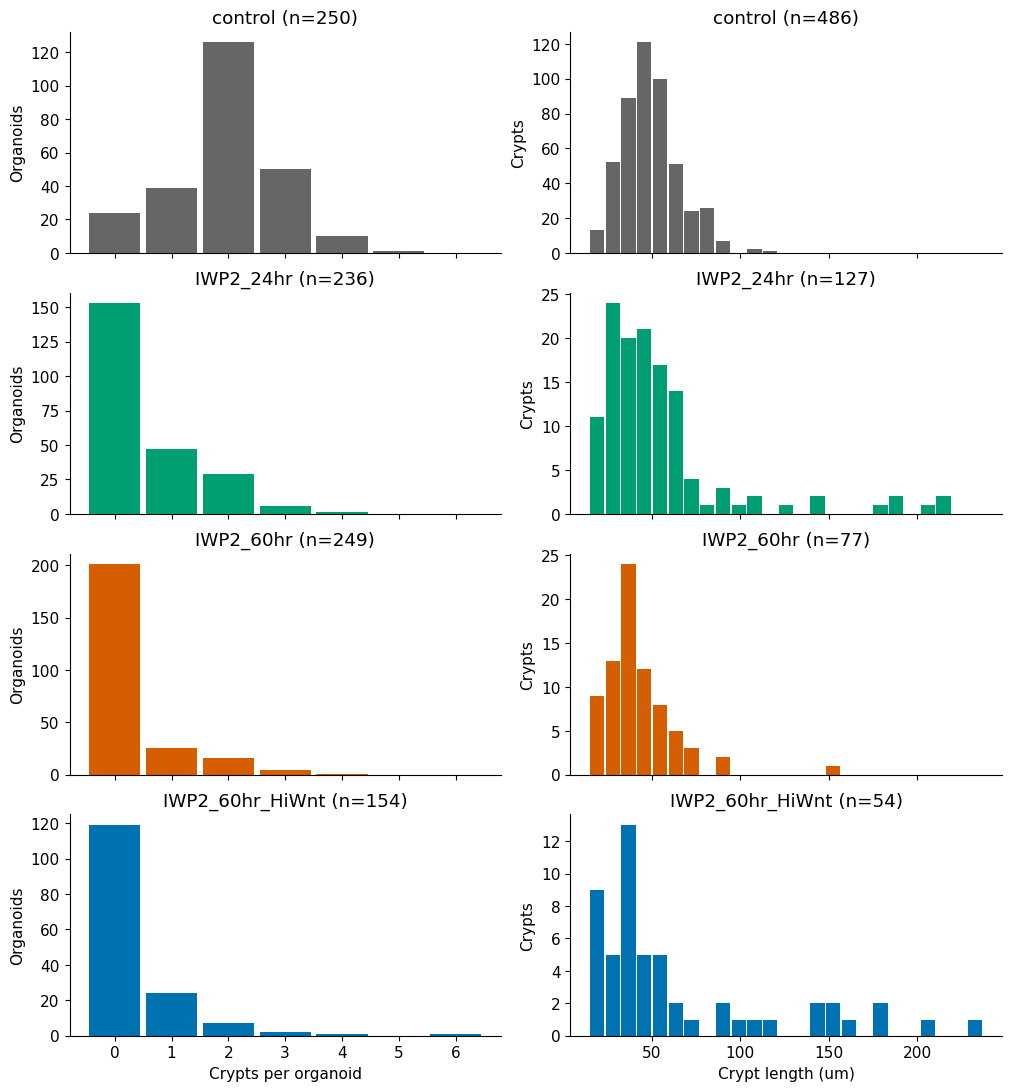

In [5]:
count_edges = np.arange(int(organoid_table.n_crypts.max()) + 2) - 0.5
valid_lengths = crypt_table.loc[crypt_table.valid_length.astype(bool), 'length_um'].to_numpy(dtype=float)
length_edges = np.histogram_bin_edges(valid_lengths, bins=LENGTH_BINS)
fig_distributions, axes = plt.subplots(len(CONDITION_ORDER), 2,
    figsize=(10, 2.7 * len(CONDITION_ORDER)), sharex='col', squeeze=False, constrained_layout=True)
histogram_rows = []
for row, condition in enumerate(CONDITION_ORDER):
    counts = organoid_table.loc[organoid_table.condition == condition, 'n_crypts'].to_numpy()
    lengths = crypt_table.loc[(crypt_table.condition == condition) &
                             crypt_table.valid_length.astype(bool), 'length_um'].to_numpy(dtype=float)
    for col, (values, edges, measure, ylabel) in enumerate([
        (counts, count_edges, 'n_crypts', 'Organoids'),
        (lengths, length_edges, 'length_um', 'Crypts'),
    ]):
        ax = axes[row, col]
        frequencies, _ = np.histogram(values, bins=edges)
        ax.bar((edges[:-1] + edges[1:]) / 2, frequencies, width=np.diff(edges) * 0.9,
               color=CONDITION_COLORS[condition])
        ax.set_title(f'{condition} (n={len(values)})')
        ax.set_ylabel(ylabel)
        ax.set_ylim(bottom=0)
        if not len(values):
            ax.text(0.5, 0.5, 'No observations', transform=ax.transAxes, ha='center')
        for left, right, frequency in zip(edges[:-1], edges[1:], frequencies):
            histogram_rows.append(dict(condition=condition, measure=measure,
                bin_left=left, bin_right=right, frequency=int(frequency),
                n_observations=len(values)))
    axes[row, 0].set_xticks(np.arange(len(count_edges) - 1))
axes[-1, 0].set_xlabel('Crypts per organoid')
axes[-1, 1].set_xlabel('Crypt length (um)')
histogram_table = pd.DataFrame(histogram_rows)
plt.show()


In [6]:
if EXPORT:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    for name, table in [('crypt_counts_by_organoid', organoid_table),
                        ('crypt_lengths_by_crypt', crypt_table),
                        ('crypt_summary_by_condition', summary_table),
                        ('crypt_distribution_plot_data', histogram_table),
                        ('skipped_segmentation_files', skipped_files)]:
        table.to_csv(EXPORT_DIR / f'{name}.csv', index=False)
    for name, fig in [('mean_crypt_count', fig_mean), ('crypt_distributions', fig_distributions)]:
        fig.savefig(EXPORT_DIR / f'{name}.svg', bbox_inches='tight')
        fig.savefig(EXPORT_DIR / f'{name}.png', dpi=180, bbox_inches='tight')
    print(f'Exported figures and tables to {EXPORT_DIR}')


Exported figures and tables to /home/fmoller/Projects/LearningOrganoids/OrganoGraph/exports/crypt_perturbations/perturbations_day3p5
